# TP 3 — Vision par ordinateur


In [1]:
%pip install numpy matplotlib opencv-python

In [2]:
%pip install "setuptools<81" dlib face_recognition

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 MB 48.3 MB/s  0:00:02
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for face-recognition-models: filename=face_recognition_models-0.3.0-py2.py3-none-any.whl size=100566240 sha256=58f2ae097221c9dbed0019a61166eddcfeabf98f0009199d1658be3c7792f950
  Stored in directory: /root/.cache/pip/wheels/39/20/47/6b647a3457f0e36c161b2516a5bd7f29f6bbd5e3a67c46a710
Successfully built face-recognition-models
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [face_recognition]


In [3]:
%pip install torch torchvision ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 11.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [4]:
%pip install wheel ninja
%pip install --no-build-isolation -v "git+https://github.com/facebookresearch/detectron2.git"

Using pip 26.2.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-8d2a3rgb
  Running command git version
  git version 2.43.0
  Running command git clone --filter=blob:none https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-8d2a3rgb
  Cloning into '/tmp/pip-req-build-8d2a3rgb'...
  Updating files:   0% (2/828)
  Updating files:   1% (9/828)
  Updating files:   2% (17/828)
  Updating files:   3% (25/828)
  Updating files:   4% (34/828)
  Updating files:   5% (42/828)
  Updating files:   6% (50/828)
  Updating files:   7% (58/828)
  Updating files:   8% (67/828)
  Updating files:   9% (75/828)
  Updating files:  10% (83/828)
  Updating files:  11% (92/828)
  Updating files:  12% (100/828)
  Updating files:  13% (108/828)
  Updating files:  14% (116/828)
  Updating files:  15% (125/828)
  Updating files:  16% (133/828)
  Updating files:  17% (141/828)
  Updating files:  18% 

In [5]:
from pathlib import Path
import time, sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
DATA = Path("/content")
assert DATA.is_dir(), 'Extraire le ZIP entier et conserver le dossier images à côté du notebook.'
OUT = Path('tp3_resultats'); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11})
def montrer(images, titres, fichier=None):
    fig, axes = plt.subplots(1, len(images), figsize=(6*len(images), 5), squeeze=False)
    for ax, im, titre in zip(axes[0], images, titres):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap='gray')
        ax.set_title(titre); ax.axis('off')
    fig.tight_layout()
    if fichier: fig.savefig(OUT / fichier, bbox_inches='tight')
    plt.show()
print('Python', sys.version.split()[0], '| OpenCV', cv2.__version__)

Python 3.13.18 | OpenCV 5.0.0


In [6]:
from pathlib import Path
import cv2

DATA = Path("/content")

print("Fichiers présents :", [p.name for p in DATA.iterdir()])
print("Image trouvée :", (DATA / "image_objects.jpg").exists())

img = cv2.imread(str(DATA / "image_objects.jpg"))

if img is not None:
    print("Image chargée correctement !")
else:
    print("Vérifie que image_objects.jpg est bien importée dans /content.")

Fichiers présents : ['.config', 'people.jpg', 'test.jpg', 'image_objects.jpg', 'tp3_resultats', 'other.jpg', 'ref.jpg', 'sample_data']
Image trouvée : True
Image chargée correctement !


### Origine des images
Scène : [bus.jpg — Ultralytics](https://github.com/ultralytics/ultralytics/blob/main/ultralytics/assets/bus.jpg). Visages de démonstration : [exemples face_recognition](https://github.com/ageitgey/face_recognition/tree/master/examples) (`obama.jpg`, `obama2.jpg`, `biden.jpg`). Les deux premières photos servent de référence et de test de la même personne ; la troisième est un contrôle négatif.

## Exercice 1 — Image, niveaux de gris, contours

In [7]:
from google.colab import files
from pathlib import Path
import cv2

uploaded = files.upload()  # Sélectionne une seule image

if not uploaded:
    raise ValueError("Aucune image sélectionnée.")

DATA = Path("/content")
contenu = next(iter(uploaded.values()))
chemin = DATA / "image_objects.jpg"
chemin.write_bytes(contenu)

img = cv2.imread(str(chemin))

if img is None:
    raise ValueError("Sélectionne une vraie image JPG ou PNG, pas le ZIP.")

img = cv2.resize(img, (600, 800))
print("Image chargée correctement :", img.shape)

Saving image_objects.jpg to image_objects (1).jpg
Image chargée correctement : (800, 600, 3)


**Réponses.**
1. La matrice contient les intensités des pixels : `(hauteur, largeur, 3)` en **BGR**, généralement des entiers `uint8` de 0 à 255. En niveaux de gris : `(hauteur, largeur)`.
2. Le gris réduit trois canaux à un seul : moins de calculs, et une information de luminance suffisante pour de nombreux traitements de contours. On perd l'information de couleur.
3. Le filtre gaussien calcule une moyenne pondérée du voisinage. Il atténue le bruit et donc les faux contours ; un flou trop fort efface aussi les détails. `(5,5)` est la taille du noyau ; `sigma=0` laisse OpenCV calculer l'écart-type.

## Exercice 2 — Lecture et enregistrement vidéo
Démonstration reproductible : 24 images d’une scène avec déplacement horizontal simulé. Il ne s’agit pas d’une capture webcam réelle.

24 images lues et enregistrées dans video_grise.avi


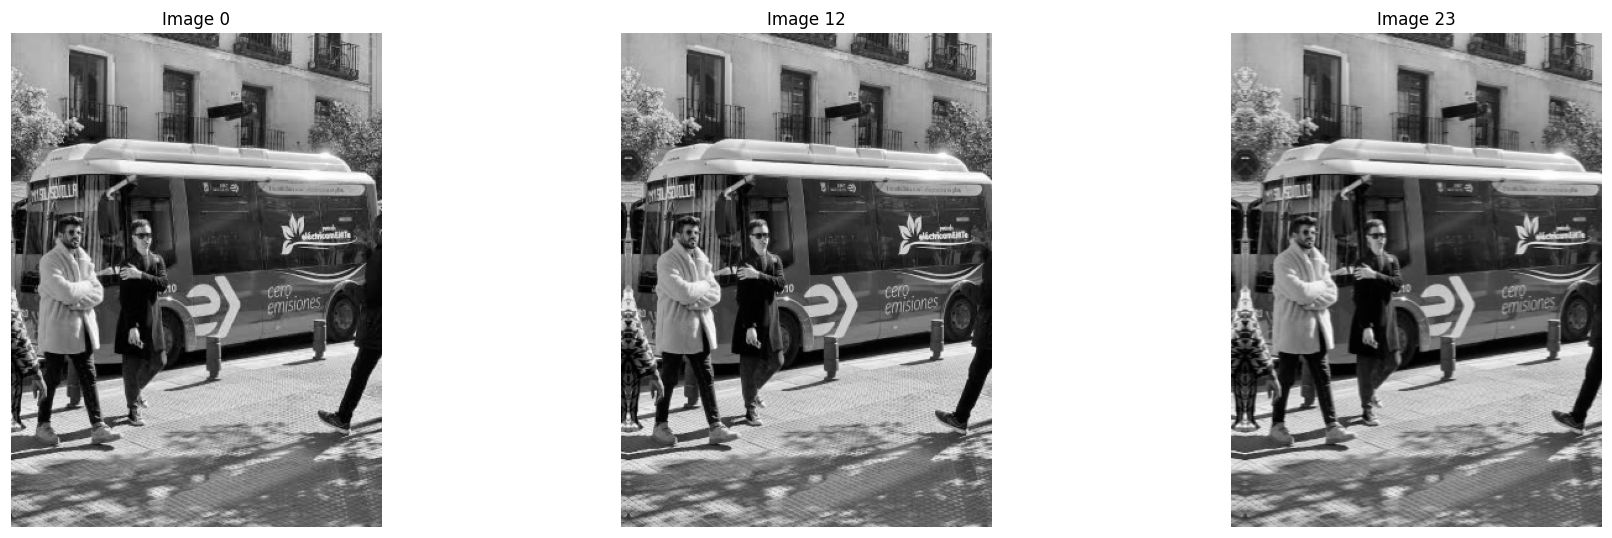

In [8]:
fps = 12; taille = (300,400)
source = str(DATA/'demo.avi')
writer = cv2.VideoWriter(source, cv2.VideoWriter_fourcc(*'MJPG'), fps, taille)
assert writer.isOpened()
base = cv2.resize(img, taille)
for i in range(24):
    frame = cv2.warpAffine(base, np.float32([[1,0, i/2],[0,1,0]]), taille, borderMode=cv2.BORDER_REFLECT)
    writer.write(frame)
writer.release()
cap = cv2.VideoCapture(source)
writer = cv2.VideoWriter(str(OUT/'video_grise.avi'),cv2.VideoWriter_fourcc(*'MJPG'),fps,taille,isColor=False)
assert cap.isOpened() and writer.isOpened()
count = 0; apercus=[]
while True:
    ok, frame = cap.read()
    if not ok: break
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    writer.write(gris)
    if count in (0,12,23): apercus.append(gris.copy())
    count += 1
cap.release(); writer.release()
print(f'{count} images lues et enregistrées dans video_grise.avi')
montrer(apercus, ['Image 0','Image 12','Image 23'],'ex2.png')

In [9]:
def webcam_grise(source=0, destination='webcam_grise.avi'):
    """À appeler sur un PC avec webcam et OpenCV GUI ; quitter avec q."""
    cap = cv2.VideoCapture(source)
    writer = None
    try:
        if not cap.isOpened(): raise RuntimeError('Caméra/vidéo inaccessible')
        fps = cap.get(cv2.CAP_PROP_FPS)
        fps = fps if np.isfinite(fps) and fps > 0 else 25.0
        while True:
            ok, frame = cap.read()
            if not ok: break
            gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            if writer is None:
                h,w = gris.shape
                writer = cv2.VideoWriter(destination, cv2.VideoWriter_fourcc(*'MJPG'), fps, (w,h), False)
                if not writer.isOpened(): raise RuntimeError('Enregistrement impossible')
            writer.write(gris)
            cv2.imshow('Video grise - q pour quitter', gris)
            if cv2.waitKey(max(1,round(1000/fps))) & 0xFF == ord('q'): break
    finally:
        cap.release()
        if writer is not None: writer.release()
        cv2.destroyAllWindows()
print('Fonction webcam_grise définie ; appel manuel sur PC : webcam_grise(0)')

Fonction webcam_grise définie ; appel manuel sur PC : webcam_grise(0)


**Réponse.** Pour lire un fichier, remplacer `0` par son chemin. `cap.read()` renvoie `False` à la fin du fichier. Le traitement reste identique. Le FPS du fichier permet de régler le délai d'affichage ; sans délai, la lecture avance aussi vite que le calcul le permet.

## Exercice 3 — Detectron2 / Mask R-CNN
Inférence CPU sur la même image que YOLO. Les boîtes, classes et masques ci-dessous sont des prédictions réelles.

/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
model_final_f10217.pkl: 178MB [00:01, 100MB/s]                           
/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch

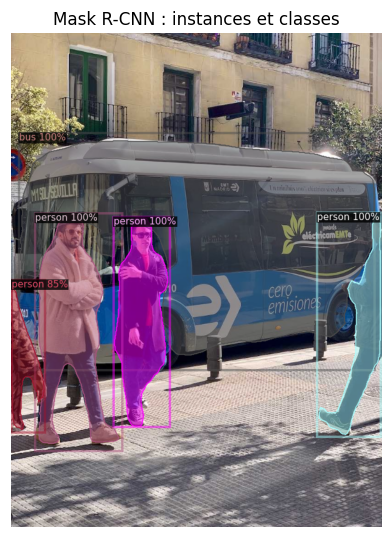

Objets détectés : {'person': 4, 'bus': 1}
person          0.999
person          0.998
person          0.997
bus             0.996
person          0.848


In [10]:
import torch
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.engine import DefaultPredictor
from detectron2.data import MetadataCatalog
from detectron2.utils.visualizer import Visualizer
from collections import Counter
torch.set_num_threads(2)
CONFIG = 'COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml'
cfg = get_cfg(); cfg.merge_from_file(model_zoo.get_config_file(CONFIG))
cfg.MODEL.DEVICE = 'cpu'
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CONFIG)
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
cfg.INPUT.MIN_SIZE_TEST = 640; cfg.INPUT.MAX_SIZE_TEST = 1000
predictor = DefaultPredictor(cfg)
metadata = MetadataCatalog.get(cfg.DATASETS.TRAIN[0])
outputs = predictor(img)
instances = outputs['instances'].to('cpu')
vis = Visualizer(img[:,:,::-1], metadata=metadata, scale=1).draw_instance_predictions(instances)
montrer([vis.get_image()[:,:,::-1]], ['Mask R-CNN : instances et classes'], 'ex3.png')
classes = [metadata.thing_classes[i] for i in instances.pred_classes.tolist()]
print('Objets détectés :',dict(Counter(classes)))
for nom,score in zip(classes,instances.scores.tolist()): print(f'{nom:15s} {score:.3f}')

Seuil 0.3 : 6 instances ; {'person': 4, 'bus': 1, 'banana': 1}
Seuil 0.5 : 5 instances ; {'person': 4, 'bus': 1}
Seuil 0.8 : 5 instances ; {'person': 4, 'bus': 1}


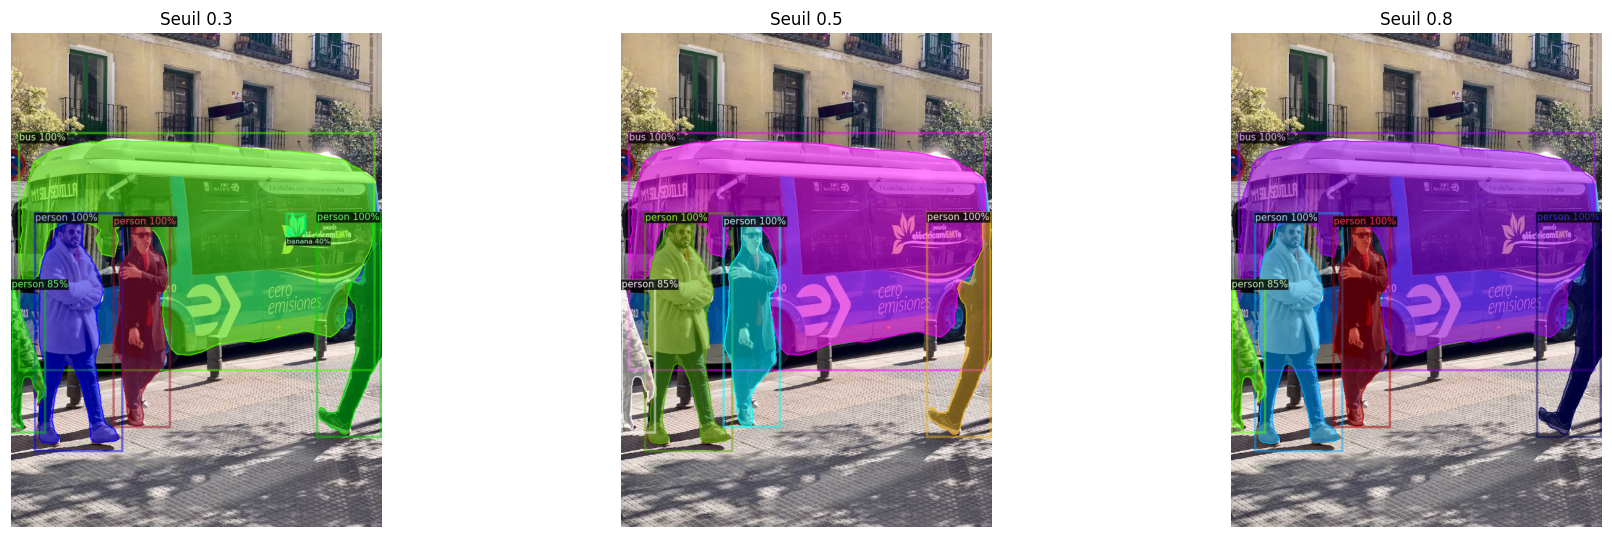

Temps Mask R-CNN (s) : [3.55721927 3.59231162 5.06533861]


In [11]:
seuils = [0.3,0.5,0.8]
images_seuils=[]
for seuil in seuils:
    predictor.model.roi_heads.box_predictor.test_score_thresh = seuil
    inst = predictor(img)['instances'].to('cpu')
    print(f'Seuil {seuil} : {len(inst)} instances ;',dict(Counter(metadata.thing_classes[i] for i in inst.pred_classes.tolist())))
    v = Visualizer(img[:,:,::-1],metadata=metadata).draw_instance_predictions(inst)
    images_seuils.append(v.get_image()[:,:,::-1])
predictor.model.roi_heads.box_predictor.test_score_thresh = 0.5
montrer(images_seuils,[f'Seuil {s}' for s in seuils],'ex3_seuils.png')

# Mesurer puis libérer Mask R-CNN avant de charger les autres modèles.
def mesurer(fn,n=3):
    fn() # échauffement, exclu des mesures
    mesures=[]
    for _ in range(n):
        debut=time.time(); fn(); mesures.append(time.time()-debut)
    return np.array(mesures)
t_mask=mesurer(lambda: predictor(img))
print('Temps Mask R-CNN (s) :',t_mask)
import gc, ctypes
del predictor, outputs, instances, inst
gc.collect()
try: ctypes.CDLL('libc.so.6').malloc_trim(0)
except OSError: pass


**Réponses.** La liste exacte des classes détectées et leurs effectifs est calculée au-dessus. Le seuil filtre les scores de confiance : l'augmenter écarte les prédictions moins confiantes, mais peut faire perdre des objets réels (rappel plus faible). L'abaisser conserve davantage de candidats, avec un risque de faux positifs. Le score n'est pas une garantie de justesse. Un masque distingue les pixels de chaque instance ; une boîte donne seulement un rectangle.

**Observation sur cette image :** à 0,5 et 0,8, Mask R-CNN détecte 4 personnes et 1 bus. À 0,3, il ajoute une prédiction « banana » qui semble être un faux positif au vu de la scène : cela illustre le risque d’abaisser le seuil.

## Exercice 4 — Détection de visages avec Dlib

In [12]:
from google.colab import files
from pathlib import Path
import cv2

uploaded = files.upload()  # Sélectionne people.jpg

if not uploaded:
    raise ValueError("Aucune image sélectionnée.")

chemin = Path("/content/people.jpg")
chemin.write_bytes(next(iter(uploaded.values())))

people = cv2.imread(str(chemin))

if people is None:
    raise ValueError("Image illisible : sélectionne le fichier people.jpg.")

print("Image des visages chargée :", people.shape)

Saving people.jpg to people (1).jpg
Image des visages chargée : (500, 620, 3)


Nombre de visages détectés : 2


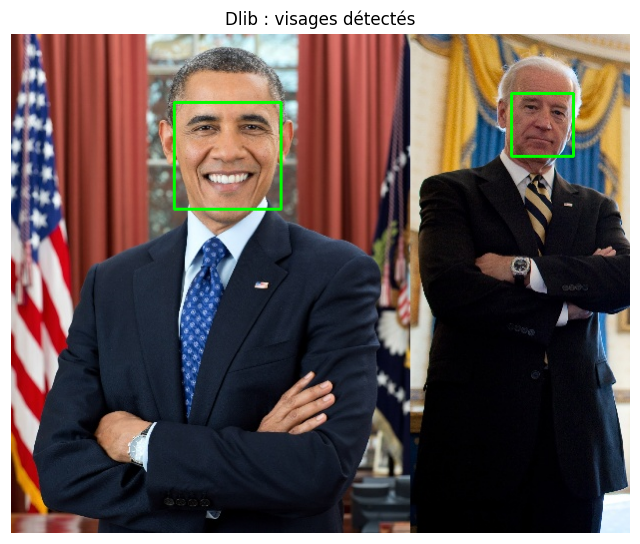

In [13]:
import dlib
import face_recognition
import face_recognition_models
detector = dlib.get_frontal_face_detector()
faces = detector(cv2.cvtColor(people,cv2.COLOR_BGR2GRAY),1)
annote = people.copy()
for face in faces:
    cv2.rectangle(annote,(face.left(),face.top()),(face.right(),face.bottom()),(0,255,0),2)
print('Nombre de visages détectés :',len(faces))
montrer([annote],['Dlib : visages détectés'],'ex4.png')

## Exercice 5 — Comparaison de visages
On compare un encodage de référence aux visages de chaque image test. Le contrôle négatif teste une autre personne.

test.jpg, visage 1 : distance=0.3644, même personne ? True


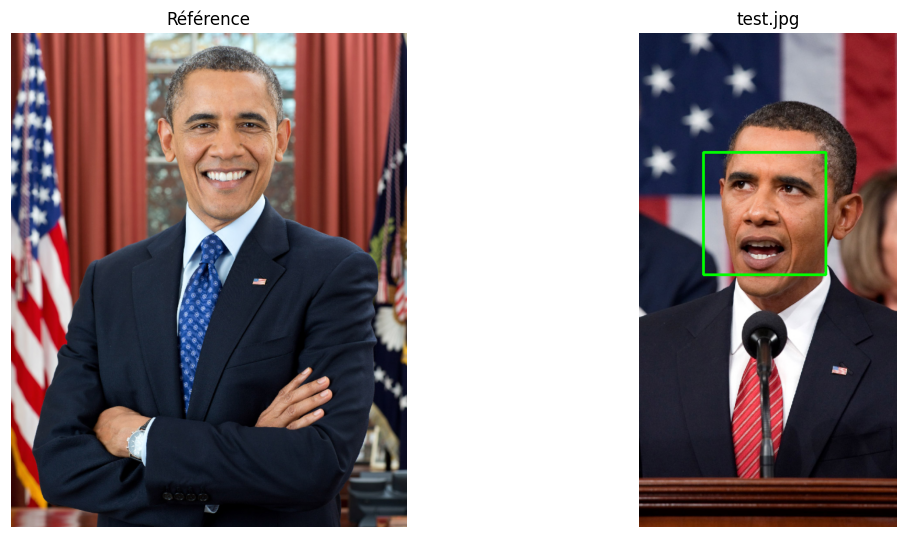

other.jpg, visage 1 : distance=0.8505, même personne ? False


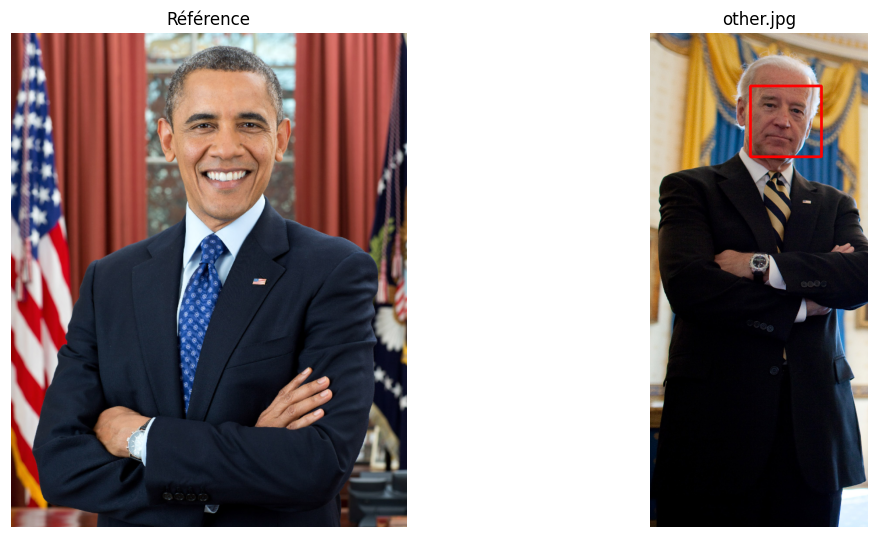

In [14]:
def charger_rgb(nom):
    bgr=cv2.imread(str(DATA/nom))
    if bgr is None: raise FileNotFoundError(nom)
    h,w=bgr.shape[:2]
    if max(h,w)>900: bgr=cv2.resize(bgr,(round(w*900/max(h,w)),round(h*900/max(h,w))))
    return cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
ref = charger_rgb('ref.jpg')
refs = face_recognition.face_encodings(ref)
if len(refs)!=1: raise ValueError('La référence doit contenir exactement un visage')
enc_ref=refs[0]; tolerance=0.6
for nom in ['test.jpg','other.jpg']:
    rgb=charger_rgb(nom)
    boxes=face_recognition.face_locations(rgb,model='hog')
    encs=face_recognition.face_encodings(rgb,boxes)
    rendu=cv2.cvtColor(rgb,cv2.COLOR_RGB2BGR)
    if not encs: print(nom,': aucun visage')
    for i,(box,enc) in enumerate(zip(boxes,encs)):
        distance=float(face_recognition.face_distance([enc_ref],enc)[0])
        meme=bool(face_recognition.compare_faces([enc_ref],enc,tolerance=tolerance)[0])
        print(f'{nom}, visage {i+1} : distance={distance:.4f}, même personne ? {meme}')
        top,right,bottom,left=box
        cv2.rectangle(rendu,(left,top),(right,bottom),(0,255,0) if meme else (0,0,255),3)
    montrer([cv2.cvtColor(ref,cv2.COLOR_RGB2BGR),rendu],['Référence',nom],'ex5_'+nom+'.png')

**Réponses.**
1. `face_encodings` renvoie une liste d'encodages, un par visage détecté. Avec `[0]`, on ne compare que le premier et on risque une erreur si la liste est vide. Ici on vérifie la référence, puis on parcourt tous les visages de chaque test.
2. La qualité dépend de la lumière, de la pose, de la résolution, des occlusions et du seuil. Une tolérance plus faible est plus stricte : moins de fausses acceptations, mais davantage de faux rejets. On ne peut pas déduire une précision réelle de deux photos ; il faudrait un jeu représentatif et mesurer les faux positifs/négatifs. La distance entre encodages n'est pas un pourcentage de certitude.

## Exercice 6 — 68 landmarks et EAR

Visages : 2
Parties : ['chin', 'left_eyebrow', 'right_eyebrow', 'nose_bridge', 'nose_tip', 'left_eye', 'right_eye', 'top_lip', 'bottom_lip']


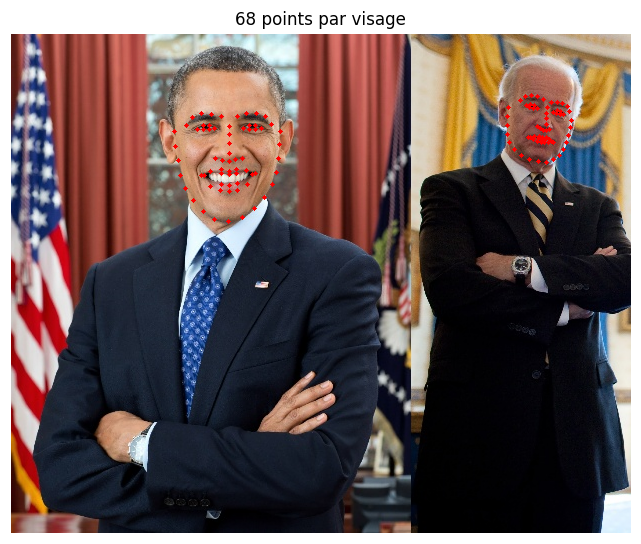

Visage 1 : EAR gauche=0.235 ; droit=0.222
Visage 2 : EAR gauche=0.295 ; droit=0.253


In [15]:
rgb_people = cv2.cvtColor(people,cv2.COLOR_BGR2RGB)
landmarks_list = face_recognition.face_landmarks(rgb_people,model='large')
print('Visages :',len(landmarks_list))
print('Parties :',list(landmarks_list[0]))
# Accès direct au prédicteur Dlib pour dessiner exactement ses 68 indices.
shape_predictor=dlib.shape_predictor(face_recognition_models.pose_predictor_model_location())
landmark_img=people.copy()
for rect in faces:
    shape=shape_predictor(rgb_people,rect)
    assert shape.num_parts==68
    for i in range(68):
        p=shape.part(i); cv2.circle(landmark_img,(p.x,p.y),2,(0,0,255),-1)
montrer([landmark_img],['68 points par visage'],'ex6.png')
def ear(eye):
    p=np.asarray(eye,dtype=float)
    horizontal=np.linalg.norm(p[0]-p[3])
    return float((np.linalg.norm(p[1]-p[5])+np.linalg.norm(p[2]-p[4]))/(2*horizontal)) if horizontal>0 else np.nan
for i,lm in enumerate(landmarks_list):
    print(f'Visage {i+1} : EAR gauche={ear(lm["left_eye"]):.3f} ; droit={ear(lm["right_eye"]):.3f}')

**Réponses.** Les groupes sont `chin`, `left_eyebrow`, `right_eyebrow`, `nose_bridge`, `nose_tip`, `left_eye`, `right_eye`, `top_lip`, `bottom_lip`. Les groupes des lèvres partagent certains points : sommer leurs tailles ne donne donc pas nécessairement 68. Le prédicteur Dlib possède bien 68 indices.

Pour les six points ordonnés d'un œil :
$$EAR=\frac{\|p_2-p_6\|+\|p_3-p_5\|}{2\|p_1-p_4\|}.$$
L'EAR diminue lorsque l'œil se ferme. Un passage bref sous un seuil calibré (par exemple 0,20 comme valeur initiale) peut indiquer un clignement. Une fermeture continue supérieure à 2 secondes peut déclencher une alerte. Utiliser des timestamps et réinitialiser le compteur si les yeux s'ouvrent ou si le visage est perdu. Une photo isolée ne permet pas de conclure à une somnolence.

## Exercice 7 — YOLO : détection, segmentation et temps d’inférence
Les deux modèles sont chronométrés séparément pour limiter la mémoire utilisée ; les temps de Mask R-CNN sont conservés avant sa libération.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


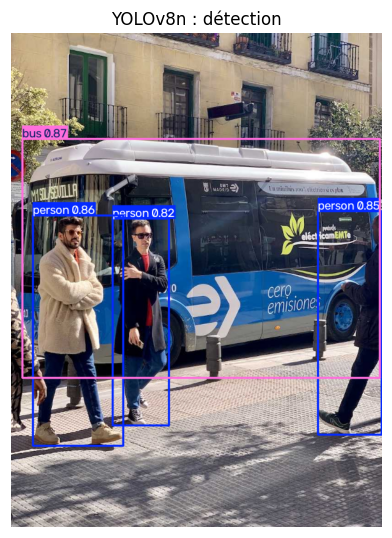

Classes : {'bus': 1, 'person': 3}
Masques du modèle de détection : None


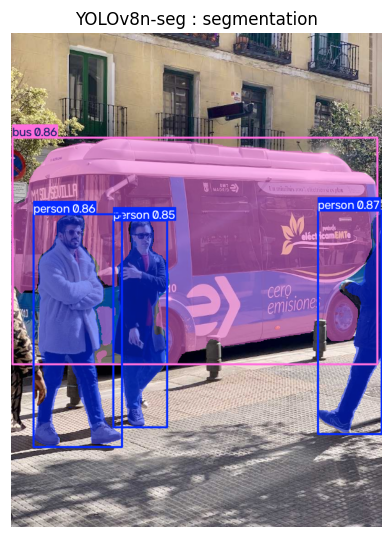

Nombre de masques : 4


7272

In [16]:
from ultralytics import YOLO
yolo = YOLO('yolov8n.pt')
yolo_result = yolo.predict(img,conf=0.5,imgsz=640,device='cpu',verbose=False)[0]
montrer([yolo_result.plot()],['YOLOv8n : détection'],'ex7_detection.png')
print('Classes :',dict(Counter(yolo_result.names[int(i)] for i in yolo_result.boxes.cls)))
print('Masques du modèle de détection :', yolo_result.masks)
yolo_seg = YOLO('yolov8n-seg.pt')
seg_result = yolo_seg.predict(img,conf=0.5,imgsz=640,device='cpu',verbose=False)[0]
montrer([seg_result.plot()],['YOLOv8n-seg : segmentation'],'ex7_segmentation.png')
print('Nombre de masques :',0 if seg_result.masks is None else len(seg_result.masks.data))
del yolo_seg, seg_result
gc.collect()

Mask R-CNN : moyenne=4071.6 ms ; écart-type=702.8 ms ; débit théorique=0.25 images/s
YOLOv8n : moyenne=106.0 ms ; écart-type=3.8 ms ; débit théorique=9.44 images/s


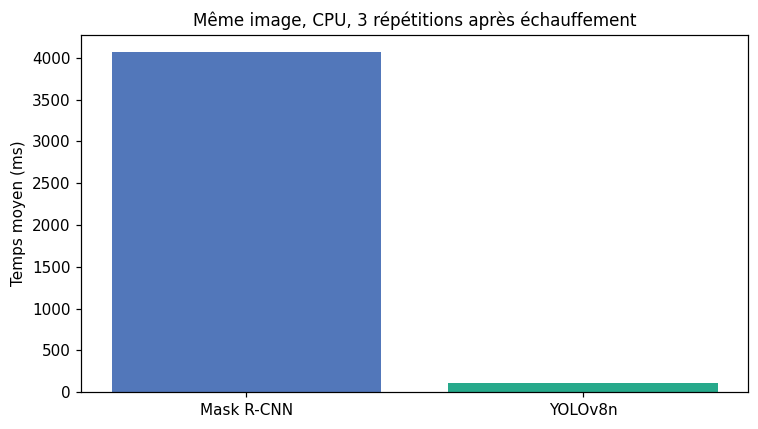

In [17]:
def mesurer(fn,n=3):
    fn() # échauffement, exclu des mesures
    mesures=[]
    for _ in range(n):
        debut=time.time(); fn(); mesures.append(time.time()-debut)
    return np.array(mesures)
# t_mask a été mesuré dans la partie Detectron2 avant libération du modèle.
t_yolo=mesurer(lambda: yolo.predict(img,conf=0.5,imgsz=640,device='cpu',verbose=False))
for nom,temps in [('Mask R-CNN',t_mask),('YOLOv8n',t_yolo)]:
    print(f'{nom} : moyenne={temps.mean()*1000:.1f} ms ; écart-type={temps.std()*1000:.1f} ms ; débit théorique={1/temps.mean():.2f} images/s')
plt.figure(figsize=(7,4))
plt.bar(['Mask R-CNN','YOLOv8n'],[t_mask.mean()*1000,t_yolo.mean()*1000],color=['#5277ba','#27a98b'])
plt.ylabel('Temps moyen (ms)'); plt.title('Même image, CPU, 3 répétitions après échauffement')
plt.tight_layout(); plt.savefig(OUT/'ex7_temps.png'); plt.show()

**Réponses.**
1. Les temps mesurés ci-dessus incluent le prétraitement, le modèle et le post-traitement, sans téléchargement, chargement des poids ni dessin. Même image, même CPU, seuil 0,5 ; chaque modèle conserve sa règle de redimensionnement (petit côté 640 pour Mask R-CNN, `imgsz=640` pour YOLO). Ces mesures locales ne sont pas un benchmark universel ni une mesure de précision.
2. `yolov8n.pt` prédit des boîtes, classes et scores, sans masques. `yolov8n-seg.pt` ajoute les masques d'instance, affichés ci-dessus.
3. YOLOv8n convient lorsque la latence et les ressources sont prioritaires : flux vidéo, robotique, comptage. Mask R-CNN est une option pour une segmentation détaillée lorsque son coût est acceptable. YOLO-seg offre aussi la segmentation avec une architecture légère. La meilleure précision dépend du jeu de test ; ce TP ne mesure pas de mAP.

**Observation :** YOLOv8n détecte ici 3 personnes et 1 bus au seuil 0,5 ; Mask R-CNN détecte une quatrième personne partiellement visible sur le bord gauche. Cela ne suffit pas à établir la supériorité générale d’un modèle.

## Mini-projet choisi — Floutage automatique des visages
**Objectif :** détecter les visages et flouter chaque région.

**README — installation :** `pip install opencv-python numpy matplotlib dlib` (ou `dlib-bin`). **Utilisation :** appeler `flouter_visages(image_bgr)` pour une image ; `flouter_video(chemin_entree, chemin_sortie)` pour une vidéo. Le résultat image et un aperçu de la vidéo sont affichés ci-dessous. La vidéo de test est construite à partir des photos : elle ne simule pas toutes les difficultés d'une vraie caméra.

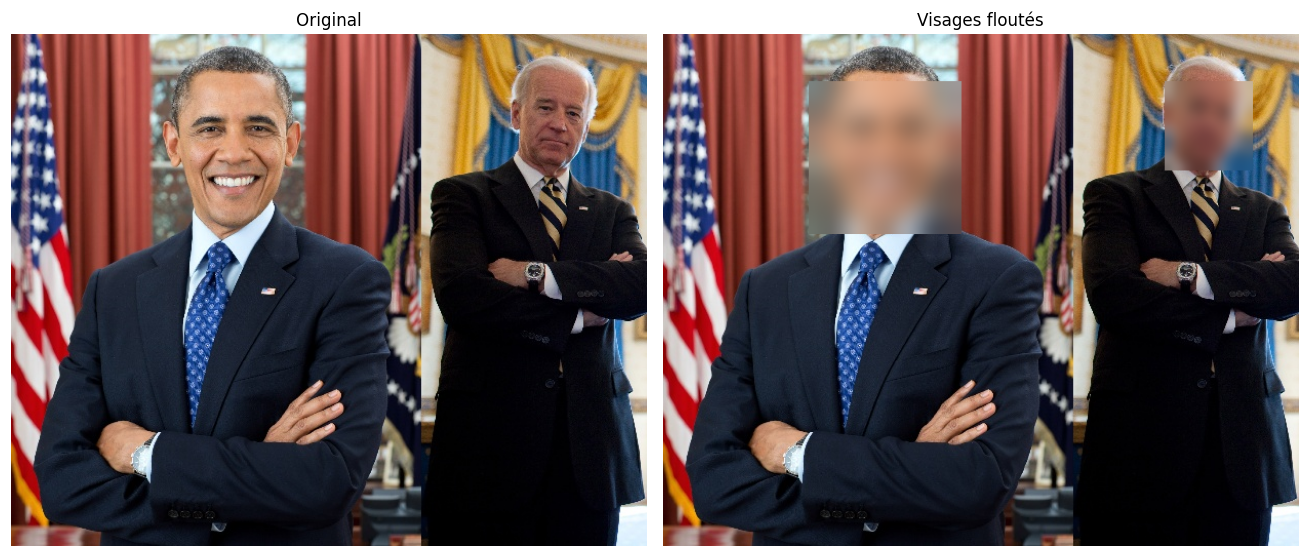

Visages floutés : 2
Vidéo traitée : 12 images


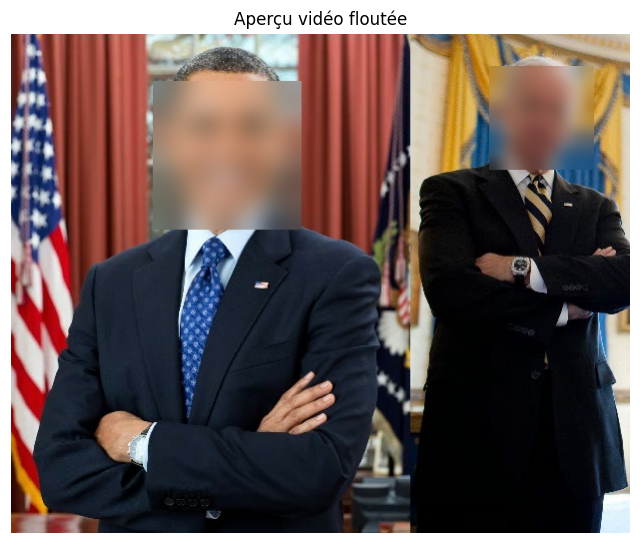

In [18]:
def flouter_visages(frame):
    resultat=frame.copy()
    rects=detector(cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY),1)
    h,w=frame.shape[:2]
    for r in rects:
        marge=int(0.2*max(r.width(),r.height()))
        x1,y1=max(0,r.left()-marge),max(0,r.top()-marge)
        x2,y2=min(w,r.right()+marge),min(h,r.bottom()+marge)
        roi=resultat[y1:y2,x1:x2]
        if roi.size:
            k=max(31,(min(roi.shape[:2])//2)|1)
            resultat[y1:y2,x1:x2]=cv2.GaussianBlur(roi,(k,k),0)
    return resultat,len(rects)
floute,n_faces=flouter_visages(people)
cv2.imwrite(str(OUT/'visages_floutes.jpg'),floute)
montrer([people,floute],['Original','Visages floutés'],'mini_projet.png')
print('Visages floutés :',n_faces)
def flouter_video(entree,sortie):
    cap=cv2.VideoCapture(str(entree)); writer=None; total=0; apercu=None
    try:
        if not cap.isOpened(): raise RuntimeError('Vidéo inaccessible')
        fps=cap.get(cv2.CAP_PROP_FPS) or 12
        while True:
            ok,frame=cap.read()
            if not ok: break
            traite,_=flouter_visages(frame)
            if writer is None:
                h,w=traite.shape[:2]
                writer=cv2.VideoWriter(str(sortie),cv2.VideoWriter_fourcc(*'MJPG'),fps,(w,h))
                if not writer.isOpened(): raise RuntimeError('Writer inaccessible')
            writer.write(traite); total+=1; apercu=traite
    finally:
        cap.release()
        if writer is not None: writer.release()
    return total,apercu
h,w=people.shape[:2]
vw=cv2.VideoWriter(str(DATA/'visages_demo.avi'),cv2.VideoWriter_fourcc(*'MJPG'),12,(w,h))
assert vw.isOpened()
for _ in range(12): vw.write(people)
vw.release()
nb,apercu=flouter_video(DATA/'visages_demo.avi',OUT/'visages_floutes.avi')
print('Vidéo traitée :',nb,'images')
montrer([apercu],['Aperçu vidéo floutée'],'mini_video.png')

**Limites du mini-projet.** Le détecteur frontal peut manquer des profils, petits visages ou visages occultés. Un floutage automatique ne garantit donc pas l'anonymisation : vérifier le résultat, adapter le détecteur et la force du flou avant toute diffusion.

## Bilan
Le notebook couvre l'acquisition, le prétraitement, la détection, la segmentation d'instance, la comparaison d'encodages faciaux et les landmarks. Les figures intégrées servent de captures de résultats ; les cellules les sauvegardent aussi dans `tp3_resultats` lors d'une nouvelle exécution.